### RAGTruth - Hallucination Detection with Classical ML

**Research questions**
1. How effectively can supervised machine-learning models classify LLM-generated responses as hallucinated or non-hallucinated?
2. Does including source context improve classification relative to response alone?

**Methodology:** Use the official RAGTruth train/test split. Within the training partition, keep related source examples together when splitting and cross-validating. Select the model on validation data, then evaluate the selected model on the official test set. The later feature-engineering extension uses training and validation data only. 

## Setup and dependencies

This notebook uses the RAGTruth dataset and downloads the two original JSONL files into `data/` if they are not already present.

Install the packages listed in `requirements.txt` in a Python environment (Python 3.13 was used for the original experiments), then start Jupyter Notebook in this project folder. Run cells from top to bottom. Results and figures will be saved to `outputs/`.

**Note:** The exploratory feature-engineering experiment comes after the original held-out test evaluation. It uses training and validation data only and does not replace the previously selected final model.

## 1. Download the original dataset
The authors publish `response.jsonl` (generated responses, labels, official split) and `source_info.jsonl` (source information). Files are placed in `data/`. If automatic download fails, download them manually from the official GitHub `dataset/` folder and place them there.

In [4]:
from pathlib import Path
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

BASE_URL = "https://raw.githubusercontent.com/ParticleMedia/RAGTruth/main/dataset"

for name in ("response.jsonl", "source_info.jsonl"):
    target = DATA_DIR / name
    if not target.exists():
        import requests
        r = requests.get(f"{BASE_URL}/{name}", timeout=120)
        r.raise_for_status()
        target.write_bytes(r.content)
    print(f"{name}: {target.stat().st_size:,} bytes")

response.jsonl: 21,458,735 bytes
source_info.jsonl: 15,117,971 bytes


## 2. Load and understand the schema

In [5]:
def read_jsonl(path):
    with open(path, "r", encoding="utf-8") as file:
        return pd.DataFrame([json.loads(line) for line in file if line.strip()])

responses = read_jsonl(DATA_DIR / "response.jsonl")
sources = read_jsonl(DATA_DIR / "source_info.jsonl")
print("Responses:", responses.shape, "Sources:", sources.shape)
print("Response columns:", responses.columns.tolist())
print("Source columns:", sources.columns.tolist())
print("Official splits:", responses["split"].value_counts(dropna=False).to_dict())
print("Response quality:", responses["quality"].value_counts(dropna=False).to_dict())
print("Raw label example:", responses["labels"].iloc[0])

Responses: (17790, 8) Sources: (2965, 5)
Response columns: ['id', 'source_id', 'model', 'temperature', 'labels', 'split', 'quality', 'response']
Source columns: ['source_id', 'task_type', 'source', 'source_info', 'prompt']
Official splits: {'train': 15090, 'test': 2700}
Response quality: {'good': 17617, 'incorrect_refusal': 144, 'truncated': 29}
Raw label example: []


## 3. Construct the binary dataset

**Classification labels:**
- `1` = The Response contains at least one hallucination.
- `0` = No hallucinations were annotated.

The dataset also includes statements marked as `implicit_true`. These may be factually correct but are not supported by the source. We count these as hallucinations because our project focuses on whether responses are supported by their sources.

**Model inputs:** Only the generated response and, when needed, the source text are used for classification. Other information, such as labels, model names, source IDs, and task types, is excluded to avoid giving the models information outside the intended text features


In [6]:
for table in (responses, sources):
    table["source_id"] = table["source_id"].astype(str)

assert sources["source_id"].is_unique, "A source_id appears more than once in source_info.jsonl"
df = responses.merge(
    sources[["source_id", "source_info", "task_type"]],
    on="source_id", how="left", validate="many_to_one"
)

def serialize_source(x):
    if isinstance(x, str):
        return x
    if isinstance(x, (dict, list)):
        return json.dumps(x, ensure_ascii=False, sort_keys=True)
    return ""

def binary_label(x):
    if not isinstance(x, list):
        raise ValueError("Expected a list of annotated hallucination spans")
    return int(len(x) > 0)

df["target"] = df["labels"].apply(binary_label)
df["response_text"] = df["response"].fillna("").astype(str).str.strip()
df["context_text"] = df["source_info"].apply(serialize_source).str.strip()

print("Unmatched sources:", df["source_info"].isna().sum())
print("Missing/empty responses:", (df["response_text"] == "").sum())
print("Missing/empty source text:", (df["context_text"] == "").sum())
print("Duplicate response IDs:", df["id"].duplicated().sum())
print("Duplicate response texts (not necessarily removable):", df["response_text"].duplicated().sum())

invalid = (df["response_text"] == "") | (df["context_text"] == "")
print("Rows excluded for essential empty input:", invalid.sum())
df = df.loc[~invalid].copy()
df["paired_text"] = (
    "SOURCE: " + df["context_text"] + "\nRESPONSE: " + df["response_text"]
)
print("Final rows:", len(df))

Unmatched sources: 0
Missing/empty responses: 0
Missing/empty source text: 0
Duplicate response IDs: 0
Duplicate response texts (not necessarily removable): 238
Rows excluded for essential empty input: 0
Final rows: 17790


## 4. Keep the official test set separate and check source IDs
The dataset contains multiple responses generated from the same source. To avoid data leakage, responses that share a source ID should not appear in both training and validation sets. 

We also check whether the official training and test sets share any source IDs. If overlapping sources are found, they are removed from the training set to keep the test set separate and ensure a fair evaluation.

In [7]:
official_train = df.loc[df["split"] == "train"].copy()
official_test = df.loc[df["split"] == "test"].copy()
if official_train.empty or official_test.empty:
    raise ValueError("Expected non-empty official train and test splits")

overlaps = set(official_train["source_id"]) & set(official_test["source_id"])
print("Official train/test shared source IDs:", len(overlaps))
if overlaps:
    print("CAUTION: dropping overlapping source groups from TRAIN to avoid source leakage.")
    official_train = official_train.loc[~official_train["source_id"].isin(overlaps)].copy()
print("Train rows:", len(official_train), "Test rows held aside:", len(official_test))

Official train/test shared source IDs: 0
Train rows: 15090 Test rows held aside: 2700


## 5. Exploratory Data Analysis (EDA)
Before training the models, we examine the dataset to better understand its structure and distribution. 

We look at the number of hallucinated and non-hallucinated responses, differences between task types, response lengths, and data quality. 

Only the official training data is used for this analysis. The test set is kept separate to avoid influencing our preprocessing decisions or model selection.

Training class counts (0=not hallucinated, 1=hallucinated):
target
0    8369
1    6721
Name: count, dtype: int64

Class fractions:
target
0    0.555
1    0.445
Name: proportion, dtype: float64

By task type:
target        0     1    All
task_type                   
Data2txt   1623  3675   5298
QA         3470  1564   5034
Summary    3276  1482   4758
All        8369  6721  15090

Response text lengths (characters):
count    15090.0
mean       801.6
std        353.6
min          7.0
25%        556.0
50%        763.0
75%        992.0
max       4007.0
Name: response_text, dtype: float64


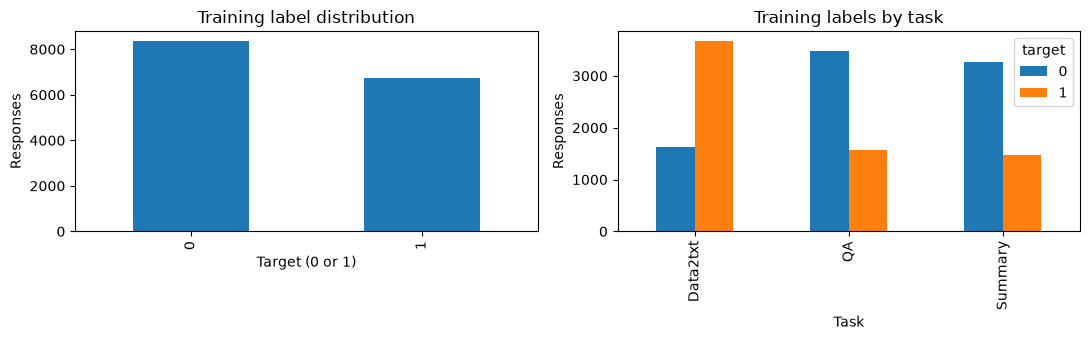

In [8]:
print("Training class counts (0=not hallucinated, 1=hallucinated):")
print(official_train["target"].value_counts().sort_index())
print("\nClass fractions:")
print(official_train["target"].value_counts(normalize=True).sort_index().round(3))
print("\nBy task type:")
print(pd.crosstab(official_train["task_type"], official_train["target"], margins=True))
print("\nResponse text lengths (characters):")
print(official_train["response_text"].str.len().describe().round(1))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
official_train["target"].value_counts().sort_index().plot.bar(ax=axs[0])
axs[0].set(title="Training label distribution", xlabel="Target (0 or 1)", ylabel="Responses")
pd.crosstab(official_train["task_type"], official_train["target"]).plot.bar(ax=axs[1])
axs[1].set(title="Training labels by task", xlabel="Task", ylabel="Responses")
plt.tight_layout()
plt.savefig(OUT_DIR / "eda_train_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Create Training and Validation Sets
We divide the official training data into separate training and validation sets to train the models and evaluate their performance.

Since multiple responses come from the same source, we group the data by `source_id` to ensure that related responses stay in the same set. This helps prevent data leakage and gives us a more reliable evaluation of the models.

In [9]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_i, val_i = next(splitter.split(official_train, official_train["target"], groups=official_train["source_id"]))
train = official_train.iloc[train_i].copy()
val = official_train.iloc[val_i].copy()
assert set(train["source_id"]).isdisjoint(set(val["source_id"]))
print("Internal training rows:", len(train), "Validation rows:", len(val))
print("Internal train rate:", round(train["target"].mean(), 3))
print("Validation rate:", round(val["target"].mean(), 3))
print("Distinct train sources:", train["source_id"].nunique())
print("Distinct val sources:", val["source_id"].nunique())

Internal training rows: 12072 Validation rows: 3018
Internal train rate: 0.445
Validation rate: 0.449
Distinct train sources: 2012
Distinct val sources: 503


In [10]:
print("Training task distribution:")
print(
    pd.crosstab(
        train["task_type"],
        train["target"],
        normalize="index"
    ).round(3)
)

print("\nValidation task distribution:")
print(
    pd.crosstab(
        val["task_type"],
        val["target"],
        normalize="index"
    ).round(3)
)

print("\nTraining and validation overlap:")
print(
    len(set(train["source_id"]) & set(val["source_id"]))
)

Training task distribution:
target         0      1
task_type              
Data2txt   0.306  0.694
QA         0.693  0.307
Summary    0.691  0.309

Validation task distribution:
target         0      1
task_type              
Data2txt   0.308  0.692
QA         0.676  0.324
Summary    0.680  0.320

Training and validation overlap:
0


## 7. Train and Compare Machine Learning Models
We train Logistic Regression and Linear SVM using two different text representations: 
- **Response only**: TF-IDF features created from the generated response.
- **Source + response**: TF-IDF features created from the source text combined with the generated response.

Both representations use the same training and validation sets to ensure a fair comparison. 

We use three-fold cross-validation to find suitable values for the regularization parameter (C). TF-IDF is fitted seperately within each training fold to prevent data leakage. 

The models are evaluated using accuracy, precision, recall, and F1-score. We use F1-score for the hallucinated class as the main measure when selecting the best model.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

RANDOM_STATE = 42
MAX_FEATURES = 5000

def metric_row(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_hallucinated": precision_score(y_true, y_pred, zero_division=0),
        "recall_hallucinated": recall_score(y_true, y_pred, zero_division=0),
        "f1_hallucinated": f1_score(y_true, y_pred, zero_division=0),
    }

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(random_state=RANDOM_STATE, max_iter=5000),
}
variants = {"Response only": "response_text", "Source + response": "paired_text"}
results = []
fitted_searches = {}

# One trivial benchmark, which always predicts the most frequent training class.
for label, field in variants.items():
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(np.zeros((len(train), 1)), train["target"])
    baseline_pred = dummy.predict(np.zeros((len(val), 1)))
    results.append({"representation": label, "model": "Majority-class baseline", "best_C": None,
                    "cv_f1": np.nan, "cv_f1_sd": np.nan, **metric_row(val["target"], baseline_pred)})

for representation, field in variants.items():
    for model_name, classifier in models.items():
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=MAX_FEATURES, min_df=2,
                                      ngram_range=(1, 2), sublinear_tf=True)),
            ("clf", classifier),
        ])
        grid = GridSearchCV(pipe, param_grid={"clf__C": [0.1, 1.0, 10.0]},
                            scoring="f1", cv=cv, n_jobs=1, refit=True,
                            error_score="raise")
        grid.fit(train[field], train["target"], groups=train["source_id"])
        pred = grid.predict(val[field])
        row = {"representation": representation, "model": model_name,
               "best_C": grid.best_params_["clf__C"],
               "cv_f1": grid.best_score_, "cv_f1_sd": grid.cv_results_["std_test_score"][grid.best_index_],
               **metric_row(val["target"], pred)}
        fitted_searches[(representation, model_name)] = grid
        results.append(row)
        print(representation, "/", model_name, row)

val_results = pd.DataFrame(results).sort_values("f1_hallucinated", ascending=False)
display(val_results.round(3))
val_results.to_csv(OUT_DIR / "validation_model_comparison.csv", index=False)

Response only / Logistic Regression {'representation': 'Response only', 'model': 'Logistic Regression', 'best_C': 10.0, 'cv_f1': np.float64(0.6681469659509042), 'cv_f1_sd': np.float64(0.006432370659728746), 'accuracy': 0.7120609675281644, 'precision_hallucinated': 0.6926131850675139, 'recall_hallucinated': 0.6440177252584933, 'f1_hallucinated': 0.667432070417145}
Response only / Linear SVM {'representation': 'Response only', 'model': 'Linear SVM', 'best_C': 1.0, 'cv_f1': np.float64(0.6634162033065697), 'cv_f1_sd': np.float64(0.005754958251910307), 'accuracy': 0.7123923127899271, 'precision_hallucinated': 0.6934713375796179, 'recall_hallucinated': 0.6432791728212703, 'f1_hallucinated': 0.6674329501915709}
Source + response / Logistic Regression {'representation': 'Source + response', 'model': 'Logistic Regression', 'best_C': 10.0, 'cv_f1': np.float64(0.6524920146735776), 'cv_f1_sd': np.float64(0.011958068342547312), 'accuracy': 0.7120609675281644, 'precision_hallucinated': 0.71032090199

,representation,model,best_C,cv_f1,cv_f1_sd,accuracy,precision_hallucinated,recall_hallucinated,f1_hallucinated
3,Response only,Linear SVM,1.0,0.663,0.006,0.712,0.693,0.643,0.667
2,Response only,Logistic Regression,10.0,0.668,0.006,0.712,0.693,0.644,0.667
4,Source + response,Logistic Regression,10.0,0.652,0.012,0.712,0.710,0.605,0.653
5,Source + response,Linear SVM,1.0,0.651,0.011,0.708,0.701,0.610,0.652
1,Source + response,Majority-class baseline,NaN,NaN,NaN,0.551,0.000,0.000,0.000
0,Response only,Majority-class baseline,NaN,NaN,NaN,0.551,0.000,0.000,0.000


## 8. Evaluate Validation Results and Select the Best Model
We compare the validation results to see which model and text representation perform best at detencting hallucinations. 

We focus mainly on F1-score, but also consider precision and recall to better understand the strengths and weaknesses of each model. 

We also investigate whether including source context improves classification compared with using only the generated response. 

The model with the highest validation F1-score is selected for final testing. The official test set is kept separate until the model has been selected to ensure a fair evaluation. 

Locked model selection based ONLY on validation:
representation            Response only
model                        Linear SVM
best_C                              1.0
cv_f1                          0.663416
cv_f1_sd                       0.005755
accuracy                       0.712392
precision_hallucinated         0.693471
recall_hallucinated            0.643279
f1_hallucinated                0.667433


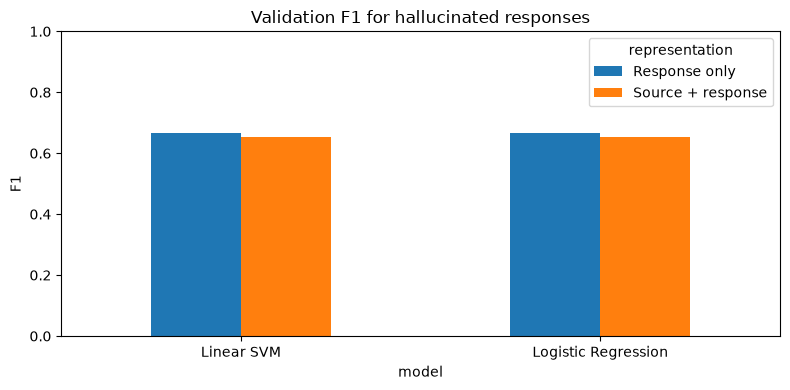

In [12]:
eligible = val_results.loc[val_results["model"] != "Majority-class baseline"].copy()
winner = eligible.sort_values(["f1_hallucinated", "recall_hallucinated"], ascending=False).iloc[0]
WINNER_REPR = winner["representation"]
WINNER_MODEL = winner["model"]
WINNER_FIELD = variants[WINNER_REPR]
WINNER_C = float(winner["best_C"])
print("Locked model selection based ONLY on validation:")
print(winner.to_string())

plot = eligible.pivot(index="model", columns="representation", values="f1_hallucinated")
ax = plot.plot.bar(figsize=(8, 4), rot=0, ylim=(0, 1))
ax.set(title="Validation F1 for hallucinated responses", ylabel="F1")
plt.tight_layout()
plt.savefig(OUT_DIR / "validation_f1_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Final Model Evaluation
The best-performing model from the validation experiements is trained again using all the official training data. 

We then evaluate the model on the separate test set to see how well it performs on unseen responses. 

The final evaluation includes accuracy, precision, recall, F1-score, and a confusion matrix to better understand the model's performance and errors. 

The test set is only used for this final evaluation. We doi not change or tune the model based on the test results, as this could lead to misleading performance estimates. 

Final held-out TEST results:
                  precision    recall  f1-score   support

No hallucination       0.81      0.78      0.80      1757
   Hallucination       0.62      0.66      0.64       943

        accuracy                           0.74      2700
       macro avg       0.71      0.72      0.72      2700
    weighted avg       0.74      0.74      0.74      2700

{'accuracy': 0.7385185185185185, 'precision_hallucinated': 0.6186186186186187, 'recall_hallucinated': 0.6553552492046659, 'f1_hallucinated': 0.6364572605561277}


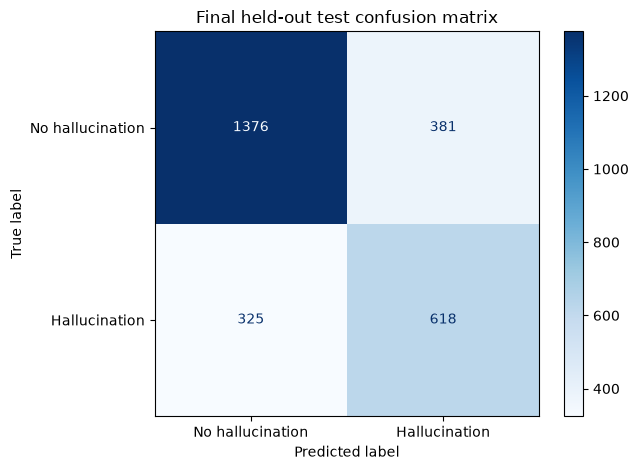

['outputs\\final_model.joblib']

In [13]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from joblib import dump

final_classifier = {
    "Logistic Regression": LogisticRegression(max_iter=2000, C=WINNER_C, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(max_iter=5000, C=WINNER_C, random_state=RANDOM_STATE),
}[WINNER_MODEL]

final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=MAX_FEATURES, min_df=2,
                              ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", final_classifier),
])
final_pipeline.fit(official_train[WINNER_FIELD], official_train["target"])
test_predictions = final_pipeline.predict(official_test[WINNER_FIELD])

print("Final held-out TEST results:")
print(classification_report(official_test["target"], test_predictions,
                            target_names=["No hallucination", "Hallucination"], zero_division=0))
final_metrics = metric_row(official_test["target"], test_predictions)
print(final_metrics)
pd.DataFrame([{"representation": WINNER_REPR, "model": WINNER_MODEL,
               "C": WINNER_C, **final_metrics}]).to_csv(OUT_DIR / "final_test_metrics.csv", index=False)

disp = ConfusionMatrixDisplay.from_predictions(
    official_test["target"], test_predictions,
    display_labels=["No hallucination", "Hallucination"], cmap="Blues", values_format="d")
disp.ax_.set_title("Final held-out test confusion matrix")
plt.tight_layout()
plt.savefig(OUT_DIR / "final_test_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()
dump(final_pipeline, OUT_DIR / "final_model.joblib")

## 10. Error Analysis
We examine ecamples where the model made incorrect predictions to better understand its limitations.

We focus on two types of errors: **False negatives** and **False positives**. We look at a few examples to investigate possible reasons for these errors, such as differences between task types or difficulties identifying factual inconsistencies. 

This analysis helps us understand the model's weakness. We do not use these results to change or retrain the model, since the final test evaluation has already been completed. 

In [14]:
error_df = official_test[["id", "task_type", "response_text", "context_text", "target"]].copy()
error_df["prediction"] = test_predictions
error_df["error_type"] = np.select(
    [(error_df.target == 1) & (error_df.prediction == 0),
     (error_df.target == 0) & (error_df.prediction == 1)],
    ["False negative", "False positive"], default="Correct"
)
print(error_df["error_type"].value_counts())
for error_type in ("False negative", "False positive"):
    print("\n", error_type)
    for _, row in error_df.loc[error_df["error_type"] == error_type].head(3).iterrows():
        print("Task:", row["task_type"], "Response:", row["response_text"][:450].replace("\n", " "))
        print("---")
# Store metadata, not full source passages or annotations.
error_df[["id", "task_type", "target", "prediction", "error_type"]].to_csv(
    OUT_DIR / "test_error_index.csv", index=False
)

error_type
Correct           1994
False positive     381
False negative     325
Name: count, dtype: int64

 False negative
Task: Summary Response: Three women, including Keonna Thomas of Philadelphia, were charged with attempting to join ISIS this week. Thomas purchased a ticket to Barcelona but was arrested before her trip. Two other women, Noelle Velentzas and Asia Siddiqui, were arrested in New York for planning to build an explosive device. The FBI cited social media messages dating back to 2013 as evidence. This brings the total number of US citizens charged with supporting terrorism t
---
Task: Summary Response: A 30-year-old Philadelphia woman, Keonna Thomas, was charged with attempting to travel to Syria to join ISIS. She was arrested on March 26 and could face 15 years in prison. Two other women, Noelle Velentzas and Asia Siddiqui, were arrested in New York for planning to build an explosive device for attacks in the US. In the past 18 months, the Justice Department has prosec

## 10.1 Exploratory Experiment: Source-Aware Feature Engineering
We conduct an additional experiment to investigate whether adding information about the relationship between the source and the response can improve hallucination detection. 

We compare the results with the original response-only models to see whether feature engineering can improve classification. 

This is an exploratory experiement using the existing training and validation data. The official test set is not used, and the experiment does not change the previously selected final model. 

In [15]:

import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def content_words(text):
    return {
        word
        for word in re.findall(r"\b[a-zA-Z]{3,}\b", text.lower())
        if word not in ENGLISH_STOP_WORDS
    }

# Extract numerical expressions.
def number_set(text):
    return {
        number.replace(",", "")
        for number in re.findall(r"\b\d+(?:[.,]\d+)*\b", text)
    }

def make_features(frame):
    output = frame[["response_text"]].copy()

    overlap_scores = []
    unsupported_numbers = []
    contains_numbers = []

    for source, response in zip(
        frame["context_text"], frame["response_text"]
    ):
        source_words = content_words(source)
        response_words = content_words(response)

        # Feature 1: Source-response word overlap
        overlap = (
            len(source_words & response_words) / len(response_words)
            if response_words else 0.0
        )

        # Feature 2: Unsupported numerical expressions
        source_numbers = number_set(source)
        response_numbers = number_set(response)

        unsupported = (
            len(response_numbers - source_numbers) / len(response_numbers)
            if response_numbers else 0.0
        )

        # Feature 3: Whether the response contains numbers
        has_numbers = float(bool(response_numbers))

        overlap_scores.append(overlap)
        unsupported_numbers.append(unsupported)
        contains_numbers.append(has_numbers)

    output["source_word_overlap"] = overlap_scores
    output["unsupported_number_fraction"] = unsupported_numbers
    output["response_has_number"] = contains_numbers

    return output


X_train_extended = make_features(train)
X_val_extended = make_features(val)

print("New training features:")
display(X_train_extended.head())

print("\nSummary of engineered features:")
display(X_train_extended.iloc[:, 1:].describe().round(3))


New training features:


,response_text,source_word_overlap,unsupported_number_fraction,response_has_number
6,"Andrew Getty, oil tycoon J. Paul Getty's grand...",0.939394,0.0,1.0
7,"Andrew Getty, one of the heirs to billions of ...",0.905660,0.0,1.0
8,"Andrew Getty, one of the heirs to billions of ...",0.933333,0.0,1.0
9,"Andrew Getty, a billionaire heir to the Getty ...",0.769231,0.0,1.0
10,"Andrew Getty, an heir to the Getty oil fortune...",0.758621,0.0,1.0



Summary of engineered features:


,source_word_overlap,unsupported_number_fraction,response_has_number
count,12072.000,12072.000,12072.000
mean,0.573,0.155,0.768
std,0.210,0.265,0.422
min,0.000,0.000,0.000
25%,0.390,0.000,1.000
50%,0.574,0.000,1.000
75%,0.750,0.250,1.000
max,1.000,1.000,1.000


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

numeric_features = [
    "source_word_overlap",
    "unsupported_number_fraction",
    "response_has_number"
]

extended_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Linear SVM": LinearSVC(
        max_iter=5000, random_state=42
    )
}

extended_cv = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=42
)

extended_results = []

for model_name, classifier in extended_models.items():

    preprocessing = ColumnTransformer(
        transformers=[
            (
                "tfidf",
                TfidfVectorizer(
                    max_features=5000,
                    min_df=2,
                    ngram_range=(1, 2),
                    sublinear_tf=True
                ),
                "response_text"
            ),
            (
                "source_features",
                StandardScaler(),
                numeric_features
            )
        ],
        transformer_weights={"source_features": 0.25}
    )

    pipeline = Pipeline([
        ("features", preprocessing),
        ("clf", classifier)
    ])

    grid = GridSearchCV(
        pipeline,
        param_grid={"clf__C": [0.1, 1.0, 10.0]},
        scoring="f1",
        cv=extended_cv,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    grid.fit(
        X_train_extended,
        train["target"],
        groups=train["source_id"]
    )

    predictions = grid.predict(X_val_extended)

    row = {
        "representation": "Response + engineered features",
        "model": model_name,
        "best_C": grid.best_params_["clf__C"],
        "cv_f1": grid.best_score_,
        "cv_f1_sd": grid.cv_results_["std_test_score"][
            grid.best_index_
        ],
        **metric_row(val["target"], predictions)
    }

    extended_results.append(row)
    print(model_name, "completed")

extended_results = pd.DataFrame(extended_results)

display(extended_results.round(3))

Logistic Regression completed
Linear SVM completed


,representation,model,best_C,cv_f1,cv_f1_sd,accuracy,precision_hallucinated,recall_hallucinated,f1_hallucinated
0,Response + engineered features,Logistic Regression,1.0,0.717,0.002,0.779,0.81,0.662,0.728
1,Response + engineered features,Linear SVM,0.1,0.715,0.003,0.779,0.82,0.651,0.726


In [17]:
original = val_results[
    (val_results["representation"] == "Response only")
    & (val_results["model"].isin([
        "Logistic Regression", "Linear SVM"
    ]))
].copy()


comparison = pd.concat(
    [original, extended_results],
    ignore_index=True
)

columns = [
    "representation",
    "model",
    "best_C",
    "cv_f1",
    "cv_f1_sd",
    "accuracy",
    "precision_hallucinated",
    "recall_hallucinated",
    "f1_hallucinated"
]

display(comparison[columns].round(3))


changes = extended_results[
    ["model", "f1_hallucinated"]
].merge(
    original[["model", "f1_hallucinated"]],
    on="model",
    suffixes=("_extended", "_original")
)

changes["f1_change"] = (
    changes["f1_hallucinated_extended"]
    - changes["f1_hallucinated_original"]
)

print("\nChange in validation F1:")
display(changes.round(4))

comparison.to_csv(
    OUT_DIR / "exploratory_feature_engineering.csv",
    index=False
)

,representation,model,best_C,cv_f1,cv_f1_sd,accuracy,precision_hallucinated,recall_hallucinated,f1_hallucinated
0,Response only,Linear SVM,1.0,0.663,0.006,0.712,0.693,0.643,0.667
1,Response only,Logistic Regression,10.0,0.668,0.006,0.712,0.693,0.644,0.667
2,Response + engineered features,Logistic Regression,1.0,0.717,0.002,0.779,0.810,0.662,0.728
3,Response + engineered features,Linear SVM,0.1,0.715,0.003,0.779,0.820,0.651,0.726



Change in validation F1:


,model,f1_hallucinated_extended,f1_hallucinated_original,f1_change
0,Logistic Regression,0.7285,0.6674,0.0610
1,Linear SVM,0.7259,0.6674,0.0585


In [18]:
from sklearn.metrics import f1_score


original_svm = fitted_searches[
    ("Response only", "Linear SVM")
]


extended_svm = grid

task_comparison = val[["task_type", "target"]].copy()

task_comparison["original_pred"] = original_svm.predict(
    val["response_text"]
)

task_comparison["extended_pred"] = extended_svm.predict(
    X_val_extended
)

rows = []

for task, group in task_comparison.groupby("task_type"):
    original_f1 = f1_score(
        group["target"], group["original_pred"]
    )

    extended_f1 = f1_score(
        group["target"], group["extended_pred"]
    )

    rows.append({
        "Task": task,
        "Original F1": original_f1,
        "Extended F1": extended_f1,
        "Improvement": extended_f1 - original_f1
    })

display(pd.DataFrame(rows).round(3))

,Task,Original F1,Extended F1,Improvement
0,Data2txt,0.861,0.885,0.024
1,QA,0.481,0.589,0.108
2,Summary,0.354,0.350,-0.004


### 10.2 Task-specific performance of the original final model

This is a descriptive breakdown of the **original selected model** on the held-out test set. It uses the predictions saved during Section 9, not the exploratory feature-engineered models. No model changes are made based on these results.

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

task_results = []

for task, group in error_df.groupby("task_type"):
    y_true = group["target"]
    y_pred = group["prediction"]

    task_results.append({
        "Task": task,
        "Samples": len(group),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "False negatives": ((y_true == 1) & (y_pred == 0)).sum(),
        "False positives": ((y_true == 0) & (y_pred == 1)).sum()
    })

task_results = pd.DataFrame(task_results)

display(task_results.round(3))

,Task,Samples,Accuracy,Precision,Recall,F1,False negatives,False positives
0,Data2txt,900,0.781,0.807,0.867,0.836,77,120
1,QA,900,0.750,0.344,0.450,0.390,88,137
2,Summary,900,0.684,0.262,0.216,0.237,160,124
